# Assignment 4: Diffusion Training from 10 to 20 Epochs

Continue training from the epoch-10 checkpoint for 10 additional epochs. The architecture, data split, normalization, and learning rate of 0.0001 remain unchanged from the main notebook.

Compare the results to assess whether additional training improves noise prediction and generated image quality.

## 1. Prepare the experiment

Load the data and define the same model and sampling procedure used in the main notebook.

In [1]:
import copy
import json
import math
import random
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, random_split
from torchvision.utils import make_grid, save_image
from tqdm.auto import tqdm

In [2]:
SEED = 42
BATCH_SIZE = 64
IMAGE_SIZE = 32
NUM_CHANNELS = 3
EPOCHS = 20
LEARNING_RATE = 0.0001
SAMPLE_STEPS = 20
RESUME_PATH = Path('C:\\Users\\Milan_Chen\\Desktop\\SEM3\\genai 5560\\ASS4\\outputs\\diffusion_from_scratch_20261118_185249_410982\\checkpoints\\diffusion_epoch_010_preserved.pth')

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if device.type == "cpu":
    torch.set_num_threads(min(4, torch.get_num_threads()))

import sys

PROJECT_DIR = None
for folder in (Path.cwd(), *Path.cwd().parents):
    for candidate in (folder, folder / "APAN_5560genai_ass1"):
        if (candidate / "app" / "main.py").is_file():
            PROJECT_DIR = candidate.resolve()
            break
    if PROJECT_DIR is not None:
        break
if PROJECT_DIR is None:
    raise FileNotFoundError("Cannot find the APAN_5560genai_ass1 project near this notebook.")
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

DATA_DIR = PROJECT_DIR / "data"
RUN_DIR = PROJECT_DIR.parent / "ASS4" / "outputs" / ("diffusion_continue_to_20_" + datetime.now().strftime("%Y%m%d_%H%M%S_%f"))
MODEL_DIR = RUN_DIR / "models"
CHECKPOINT_DIR = RUN_DIR / "checkpoints"
SAMPLE_DIR = RUN_DIR / "samples"
for directory in (MODEL_DIR, CHECKPOINT_DIR, SAMPLE_DIR):
    directory.mkdir(parents=True, exist_ok=True)
print("Device:", device)
print("Run directory:", RUN_DIR)


Device: cuda
Run directory: C:\Users\Milan_Chen\Desktop\SEM3\genai 5560\ASS4\outputs\diffusion_continue_to_20_20261118_191217_480448


In [3]:
transform = transforms.ToTensor()
full_train_dataset = torchvision.datasets.CIFAR10(
    root=DATA_DIR, train=True, download=True, transform=transform
)
train_dataset, val_dataset = random_split(
    full_train_dataset, [45000, 5000],
    generator=torch.Generator().manual_seed(SEED)
)
test_dataset = torchvision.datasets.CIFAR10(
    root=DATA_DIR, train=False, download=True, transform=transform
)
train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0,
    generator=torch.Generator().manual_seed(SEED)
)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
print("Train:", len(train_dataset), "Validation:", len(val_dataset), "Test:", len(test_dataset))

Train: 45000 Validation: 5000 Test: 10000


Image batch: torch.Size([64, 3, 32, 32])


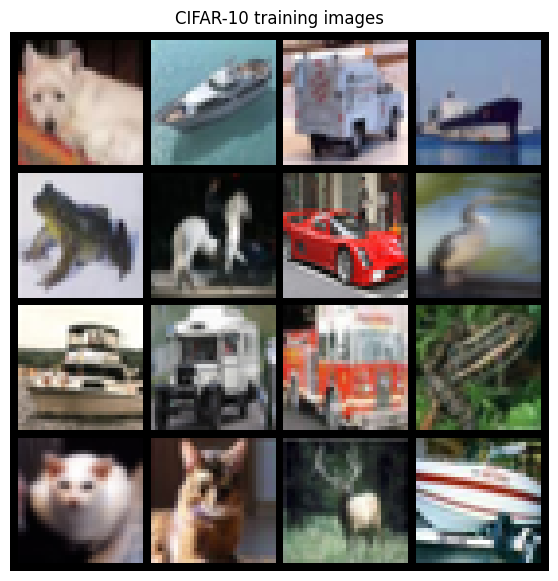

In [4]:
def show_images(images, title, nrow=4):
    grid = make_grid(images.detach().cpu(), nrow=nrow)
    plt.figure(figsize=(7, 7))
    plt.imshow(grid.permute(1, 2, 0))
    plt.title(title)
    plt.axis("off")
    plt.show()

images, labels = next(iter(train_loader))
print("Image batch:", images.shape)
show_images(images[:16], "CIFAR-10 training images")

In [5]:
channel_sum = torch.zeros(3, dtype=torch.float64)
channel_square_sum = torch.zeros(3, dtype=torch.float64)
pixel_count = 0
stats_loader = DataLoader(train_dataset, batch_size=256, shuffle=False, num_workers=0)
for batch, _ in tqdm(stats_loader, desc="Training statistics"):
    batch = batch.to(torch.float64)
    channel_sum += batch.sum(dim=(0, 2, 3))
    channel_square_sum += batch.square().sum(dim=(0, 2, 3))
    pixel_count += batch.size(0) * batch.size(2) * batch.size(3)
train_mean = (channel_sum / pixel_count).float()
train_std = (channel_square_sum / pixel_count - train_mean.double().square()).clamp_min(1e-12).sqrt().float()
print("Mean:", train_mean)
print("Standard deviation:", train_std)

Mean: tensor([0.4917, 0.4823, 0.4467])
Standard deviation: tensor([0.2471, 0.2435, 0.2616])


In [6]:
class SinusoidalEmbedding(nn.Module):
    def __init__(self, num_frequencies=16):
        super().__init__()
        self.num_frequencies = num_frequencies
        frequencies = torch.exp(
            torch.linspace(math.log(1.0), math.log(1000.0), num_frequencies)
        )
        self.register_buffer(
            "angular_speeds", 2.0 * math.pi * frequencies.view(1, 1, 1, -1)
        )

    def forward(self, x):
        x = x.expand(-1, 1, 1, self.num_frequencies)
        sin_part = torch.sin(self.angular_speeds * x)
        cos_part = torch.cos(self.angular_speeds * x)
        return torch.cat([sin_part, cos_part], dim=-1)


def offset_cosine_diffusion_schedule(diffusion_times, min_signal_rate=0.02,
                                   max_signal_rate=0.95):
    start_angle = math.acos(max_signal_rate)
    end_angle = math.acos(min_signal_rate)
    diffusion_angles = start_angle + diffusion_times * (end_angle - start_angle)
    return torch.sin(diffusion_angles), torch.cos(diffusion_angles)

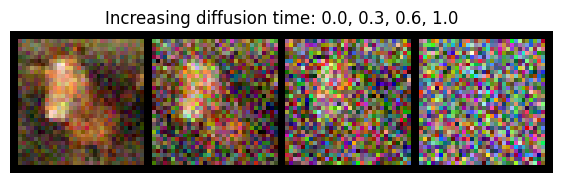

In [7]:
images, _ = next(iter(train_loader))
clean = (images[:1].repeat(4, 1, 1, 1) - train_mean.view(1, 3, 1, 1)) / train_std.view(1, 3, 1, 1)
diffusion_times = torch.tensor([0.0, 0.3, 0.6, 1.0]).view(4, 1, 1, 1)
noise_rates, signal_rates = offset_cosine_diffusion_schedule(diffusion_times)
noisy_images = signal_rates * clean + noise_rates * torch.randn_like(clean)
display_images = (noisy_images * train_std.view(1, 3, 1, 1) + train_mean.view(1, 3, 1, 1)).clamp(0, 1)
show_images(display_images, "Increasing diffusion time: 0.0, 0.3, 0.6, 1.0")

In [8]:
class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        if in_channels != out_channels:
            self.proj = nn.Conv2d(in_channels, out_channels, kernel_size=1)
        else:
            self.proj = nn.Identity()
        self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1)

    def swish(self, x):
        return x * torch.sigmoid(x)

    def forward(self, x):
        residual = self.proj(x)
        x = self.swish(self.conv1(x))
        x = self.conv2(x)
        return x + residual


class DownBlock(nn.Module):
    def __init__(self, width, block_depth, in_channels):
        super().__init__()
        self.blocks = nn.ModuleList()
        for _ in range(block_depth):
            self.blocks.append(ResidualBlock(in_channels, width))
            in_channels = width
        self.pool = nn.AvgPool2d(kernel_size=2)

    def forward(self, x, skips):
        for block in self.blocks:
            x = block(x)
            skips.append(x)
        return self.pool(x)


class UpBlock(nn.Module):
    def __init__(self, width, block_depth, in_channels):
        super().__init__()
        self.blocks = nn.ModuleList()
        for _ in range(block_depth):
            self.blocks.append(ResidualBlock(in_channels + width, width))
            in_channels = width

    def forward(self, x, skips):
        x = F.interpolate(x, scale_factor=2, mode="bilinear", align_corners=False)
        for block in self.blocks:
            skip = skips.pop()
            x = torch.cat([x, skip], dim=1)
            x = block(x)
        return x

In [9]:
class UNet(nn.Module):
    def __init__(self, image_size, num_channels, embedding_dim=32):
        super().__init__()
        if image_size % 8 != 0 or embedding_dim % 2 != 0:
            raise ValueError("image_size must be divisible by 8 and embedding_dim must be even.")
        self.initial = nn.Conv2d(num_channels, 32, kernel_size=1)
        self.num_channels = num_channels
        self.image_size = image_size
        self.embedding_dim = embedding_dim
        self.embedding = SinusoidalEmbedding(num_frequencies=embedding_dim // 2)
        self.down1 = DownBlock(32, in_channels=32 + embedding_dim, block_depth=2)
        self.down2 = DownBlock(64, in_channels=32, block_depth=2)
        self.down3 = DownBlock(96, in_channels=64, block_depth=2)
        self.mid1 = ResidualBlock(96, 128)
        self.mid2 = ResidualBlock(128, 128)
        self.up1 = UpBlock(96, in_channels=128, block_depth=2)
        self.up2 = UpBlock(64, in_channels=96, block_depth=2)
        self.up3 = UpBlock(32, in_channels=64, block_depth=2)
        self.final = nn.Conv2d(32, num_channels, kernel_size=1)
        nn.init.zeros_(self.final.weight)

    def forward(self, noisy_images, noise_variances):
        skips = []
        x = self.initial(noisy_images)
        noise_emb = self.embedding(noise_variances)
        noise_emb = F.interpolate(
            noise_emb.permute(0, 3, 1, 2),
            size=(self.image_size, self.image_size), mode="nearest"
        )
        x = torch.cat([x, noise_emb], dim=1)
        x = self.down1(x, skips)
        x = self.down2(x, skips)
        x = self.down3(x, skips)
        x = self.mid1(x)
        x = self.mid2(x)
        x = self.up1(x, skips)
        x = self.up2(x, skips)
        x = self.up3(x, skips)
        return self.final(x)

In [10]:
class DiffusionModel(nn.Module):
    def __init__(self, model, schedule_fn):
        super().__init__()
        self.network = model
        self.ema_network = copy.deepcopy(model)
        self.ema_network.requires_grad_(False)
        self.ema_network.eval()
        self.ema_decay = 0.8
        self.schedule_fn = schedule_fn
        self.register_buffer("normalizer_mean", torch.zeros(1, model.num_channels, 1, 1))
        self.register_buffer("normalizer_std", torch.ones(1, model.num_channels, 1, 1))

    def set_normalizer(self, mean, std):
        device = self.normalizer_mean.device
        mean = torch.as_tensor(mean, dtype=torch.float32, device=device).reshape(1, -1, 1, 1)
        std = torch.as_tensor(std, dtype=torch.float32, device=device).reshape(1, -1, 1, 1)
        if not torch.isfinite(mean).all() or not torch.isfinite(std).all() or (std <= 0).any():
            raise ValueError("Normalization requires finite means and positive standard deviations.")
        self.normalizer_mean.copy_(mean)
        self.normalizer_std.copy_(std)

    def denormalize(self, x):
        return (x * self.normalizer_std + self.normalizer_mean).clamp(0.0, 1.0)

    def denoise(self, noisy_images, noise_rates, signal_rates, training):
        if training:
            network = self.network
            network.train()
        else:
            network = self.ema_network
            network.eval()
        pred_noises = network(noisy_images, noise_rates.square())
        pred_images = (noisy_images - noise_rates * pred_noises) / signal_rates
        return pred_noises, pred_images

    def reverse_diffusion(self, initial_noise, diffusion_steps):
        if diffusion_steps < 1:
            raise ValueError("diffusion_steps must be positive.")
        step_size = 1.0 / diffusion_steps
        current_images = initial_noise
        for step in range(diffusion_steps):
            t = torch.full(
                (initial_noise.size(0), 1, 1, 1), 1 - step * step_size,
                device=initial_noise.device
            )
            noise_rates, signal_rates = self.schedule_fn(t)
            pred_noises, pred_images = self.denoise(
                current_images, noise_rates, signal_rates, training=False
            )
            next_noise_rates, next_signal_rates = self.schedule_fn((t - step_size).clamp(0, 1))
            current_images = next_signal_rates * pred_images + next_noise_rates * pred_noises
        return pred_images

    def generate(self, num_images, diffusion_steps, initial_noise=None):
        if initial_noise is None:
            initial_noise = torch.randn(
                num_images, self.network.num_channels,
                self.network.image_size, self.network.image_size,
                device=self.normalizer_mean.device
            )
        with torch.no_grad():
            return self.denormalize(self.reverse_diffusion(initial_noise, diffusion_steps))

    def train_step(self, images, optimizer, loss_fn):
        images = (images - self.normalizer_mean) / self.normalizer_std
        noises = torch.randn_like(images)
        diffusion_times = torch.rand((images.size(0), 1, 1, 1), device=images.device)
        noise_rates, signal_rates = self.schedule_fn(diffusion_times)
        noisy_images = signal_rates * images + noise_rates * noises
        pred_noises, _ = self.denoise(noisy_images, noise_rates, signal_rates, training=True)
        loss = loss_fn(pred_noises, noises)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        with torch.no_grad():
            for ema_param, param in zip(self.ema_network.parameters(), self.network.parameters()):
                ema_param.copy_(self.ema_decay * ema_param + (1 - self.ema_decay) * param)
        return loss.item()

    def test_step(self, images, loss_fn):
        with torch.no_grad():
            images = (images - self.normalizer_mean) / self.normalizer_std
            noises = torch.randn_like(images)
            diffusion_times = torch.rand((images.size(0), 1, 1, 1), device=images.device)
            noise_rates, signal_rates = self.schedule_fn(diffusion_times)
            noisy_images = signal_rates * images + noise_rates * noises
            pred_noises, _ = self.denoise(noisy_images, noise_rates, signal_rates, training=False)
            loss = loss_fn(pred_noises, noises)
        return loss.item()

## 2. Restore the epoch-10 checkpoint

Restore the model, EMA weights, optimizer state, normalization statistics, fixed initial noise, and training history. Continue from epoch 11 with a learning rate of 0.0001.

In [11]:
network = UNet(IMAGE_SIZE, NUM_CHANNELS)
diffusion_model = DiffusionModel(network, offset_cosine_diffusion_schedule).to(device)
diffusion_model.set_normalizer(train_mean, train_std)
optimizer = optim.Adam(diffusion_model.network.parameters(), lr=LEARNING_RATE)
loss_fn = nn.MSELoss()
fixed_noise = torch.randn(16, 3, IMAGE_SIZE, IMAGE_SIZE, device=device)
start_epoch = 0
history = []
best_val_loss = float("inf")

checkpoint = torch.load(RESUME_PATH, map_location="cpu", weights_only=True)
assert checkpoint["epoch"] == 10
diffusion_model.network.load_state_dict(checkpoint["model_state_dict"])
diffusion_model.ema_network.load_state_dict(checkpoint["ema_model_state_dict"])
diffusion_model.set_normalizer(checkpoint["normalizer_mean"], checkpoint["normalizer_std"])
diffusion_model.ema_decay = checkpoint["ema_decay"]
optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
for group in optimizer.param_groups:
    group["lr"] = LEARNING_RATE
fixed_noise = checkpoint["fixed_noise"].to(device)
start_epoch = checkpoint["epoch"]
history = copy.deepcopy(checkpoint["history"])
best_val_loss = checkpoint["best_val_loss"]
torch.save(checkpoint, CHECKPOINT_DIR / "diffusion_best.pth")

with torch.no_grad():
    prediction = network(images[:2].to(device), torch.full((2, 1, 1, 1), 0.5, device=device))
print("Noise prediction shape:", prediction.shape)
print("Completed epochs:", start_epoch)
print("Learning rate:", optimizer.param_groups[0]["lr"])
print("Next epoch:", start_epoch + 1)


Noise prediction shape: torch.Size([2, 3, 32, 32])
Completed epochs: 10
Learning rate: 0.0001
Next epoch: 11


## 3. Train and save checkpoints

Save diffusion_latest.pth with model and optimizer states for possible future continuation and diffusion_best.pth for the lowest
observed validation noise MSE. Save fixed-noise sample grids and history.json
every epoch. Validation uses fresh random noise and times, so its loss is stochastic.
Lower noise MSE alone does not prove better perceptual image quality.

This continuation loads the specified epoch-10 checkpoint and saves new results to a separate directory.

In [12]:
def train_diffusion(model, train_loader, val_loader, optimizer, loss_fn, epochs,
                    checkpoint_dir, sample_dir, fixed_noise, sample_steps,
                    start_epoch=0, history=None, best_val_loss=float("inf")):
    history = [] if history is None else history
    device = next(model.parameters()).device
    for epoch in range(start_epoch, epochs):
        train_total = 0.0
        train_count = 0
        progress = tqdm(train_loader, desc=f"Epoch {epoch + 1}/{epochs} [Train]")
        for images, _ in progress:
            loss = model.train_step(images.to(device), optimizer, loss_fn)
            train_total += loss * images.size(0)
            train_count += images.size(0)
            progress.set_postfix(loss=f"{loss:.4f}")
        val_total = 0.0
        val_count = 0
        for images, _ in tqdm(val_loader, desc="Validation"):
            loss = model.test_step(images.to(device), loss_fn)
            val_total += loss * images.size(0)
            val_count += images.size(0)
        train_loss = train_total / train_count
        val_loss = val_total / val_count
        is_best = val_loss < best_val_loss
        best_val_loss = min(best_val_loss, val_loss)
        record = {"epoch": epoch + 1, "train_loss": train_loss, "val_loss": val_loss}
        history.append(record)
        samples = model.generate(len(fixed_noise), sample_steps, fixed_noise)
        save_image(samples, sample_dir / f"epoch_{epoch + 1:03d}.png", nrow=4)
        checkpoint = {
            "epoch": epoch + 1,
            "model_state_dict": model.network.state_dict(),
            "ema_model_state_dict": model.ema_network.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "normalizer_mean": model.normalizer_mean.cpu(),
            "normalizer_std": model.normalizer_std.cpu(),
            "ema_decay": model.ema_decay,
            "fixed_noise": fixed_noise.cpu(),
            "history": history,
            "best_val_loss": best_val_loss,
            "image_size": model.network.image_size,
            "num_channels": model.network.num_channels,
        }
        torch.save(checkpoint, checkpoint_dir / "diffusion_latest.pth")
        if is_best:
            torch.save(checkpoint, checkpoint_dir / "diffusion_best.pth")
        (checkpoint_dir.parent / "history.json").write_text(json.dumps(history, indent=2))
        print(record)
        show_images(samples, f"Diffusion model: epoch {epoch + 1}")
    return history

{'epoch': 11, 'train_loss': 0.060374319254027475, 'val_loss': 0.05995245463252068}
{'epoch': 12, 'train_loss': 0.05997233284314474, 'val_loss': 0.058239804834127426}
{'epoch': 13, 'train_loss': 0.05937781110538377, 'val_loss': 0.058881376540660856}
{'epoch': 14, 'train_loss': 0.05897444312506252, 'val_loss': 0.059260516899824145}
{'epoch': 15, 'train_loss': 0.05847513310578134, 'val_loss': 0.058323140329122544}
{'epoch': 16, 'train_loss': 0.05800090410179562, 'val_loss': 0.057949109506607054}
{'epoch': 17, 'train_loss': 0.0579194690518909, 'val_loss': 0.05841212506294251}
{'epoch': 18, 'train_loss': 0.06942030018435584, 'val_loss': 0.0613551684141159}
{'epoch': 19, 'train_loss': 0.06030446418126424, 'val_loss': 0.06124755911827087}
{'epoch': 20, 'train_loss': 0.05934750966231028, 'val_loss': 0.05835572078227997}


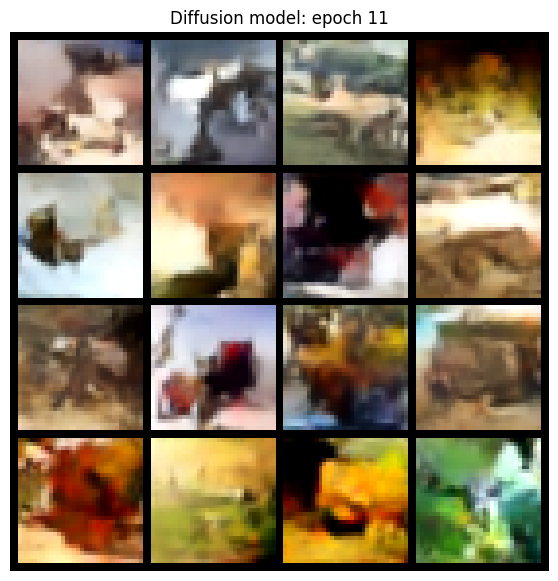

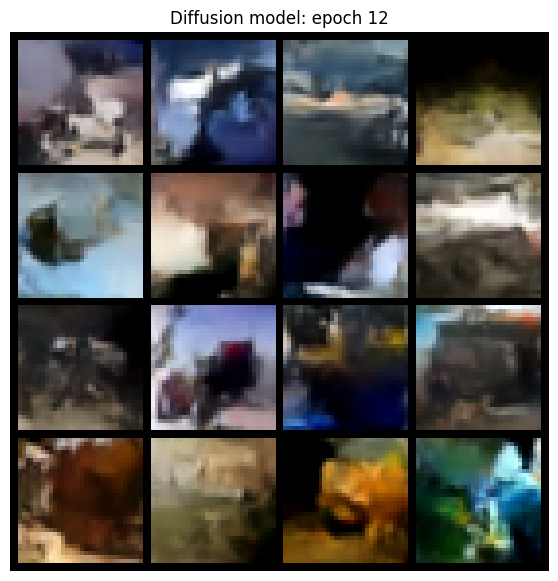

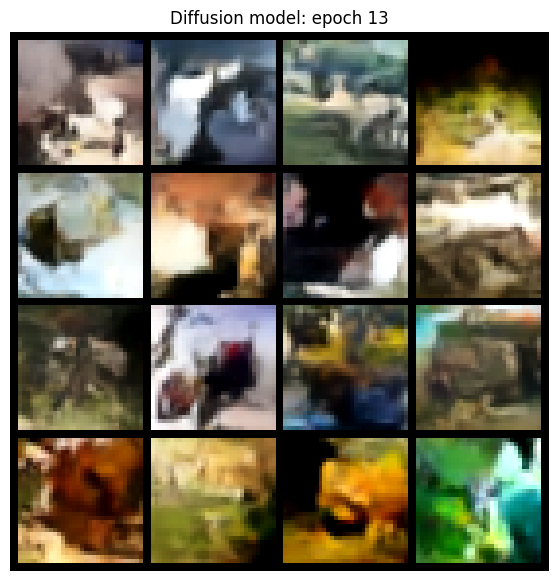

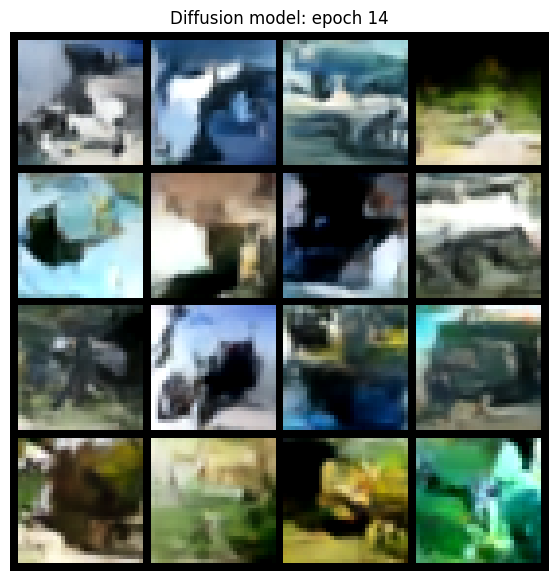

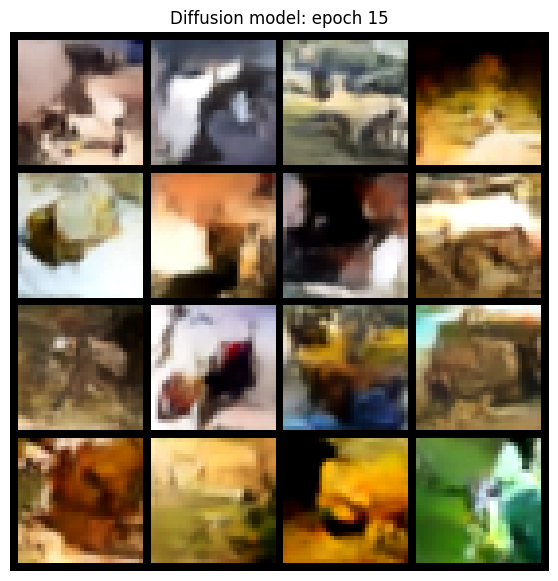

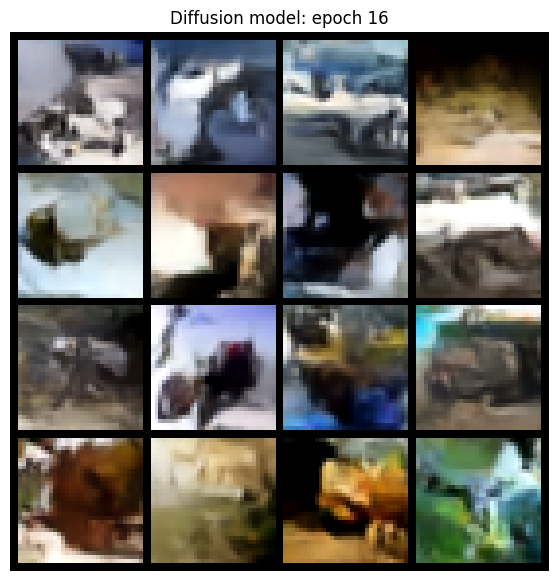

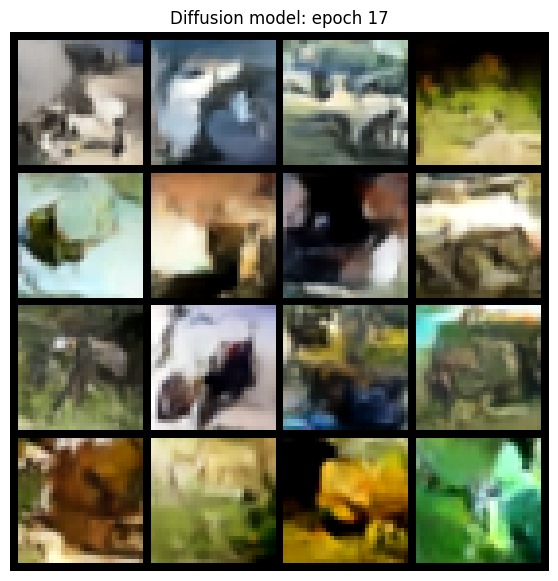

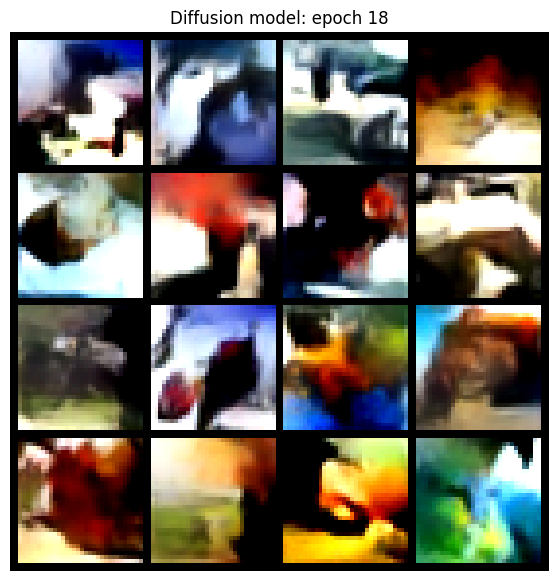

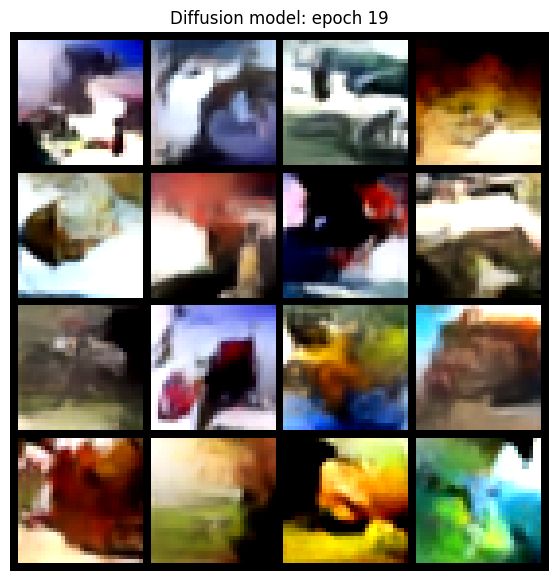

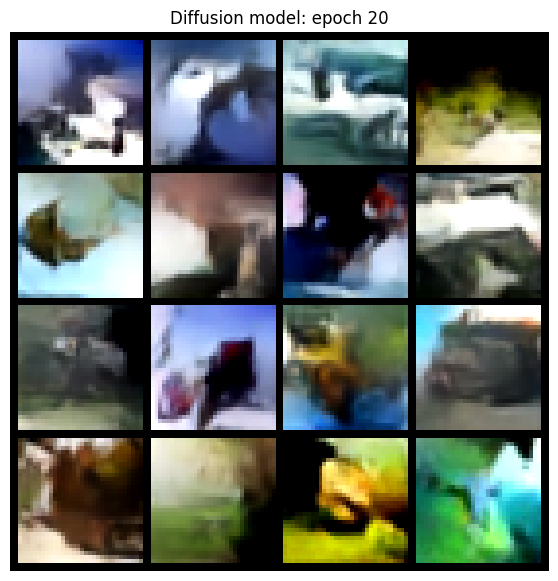

In [13]:
history = train_diffusion(
    diffusion_model, train_loader, val_loader, optimizer, loss_fn, EPOCHS,
    CHECKPOINT_DIR, SAMPLE_DIR, fixed_noise, SAMPLE_STEPS,
    start_epoch=start_epoch, history=history, best_val_loss=best_val_loss
)

## 4. Review learning curves

Epochs 1–10 are retained from the original experiment. Epochs 11–20 come from continuation. Compare validation noise MSE and fixed-noise samples; a lower MSE does not guarantee clearer objects.

The best validation noise MSE was 0.05795 at epoch 16, compared with 0.05951 at epoch 10. The selected epoch-16 model achieved test noise MSE 0.05730. Epoch 20 had validation MSE 0.05836. The exported model therefore uses epoch-16 EMA weights, whereas the final-epoch comparison figures use epoch 20.

Loss increased temporarily at epoch 18 before decreasing again. These results show that validation performance did not improve monotonically. Validation and test MSE use randomly sampled noise and times; small differences are descriptive and have not been tested for statistical significance. The test set was inspected in the earlier experiment as well, so it is not an untouched final confirmation set for this exploratory continuation.

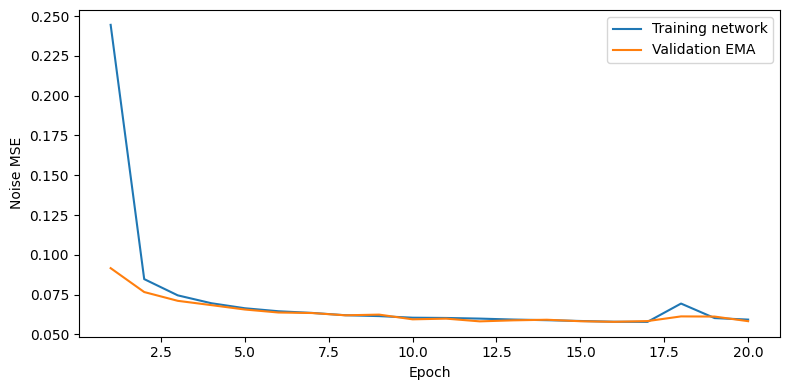

In [14]:
epochs = [row["epoch"] for row in history]
plt.figure(figsize=(8, 4))
plt.plot(epochs, [row["train_loss"] for row in history], label="Training network")
plt.plot(epochs, [row["val_loss"] for row in history], label="Validation EMA")
plt.xlabel("Epoch")
plt.ylabel("Noise MSE")
plt.legend()
plt.tight_layout()
plt.show()

## 5. Compare epochs 10 and 20

Use the same four initial noise tensors and 20 sampling steps for both checkpoints. This isolates the visual difference between the two saved EMA models under these sampling settings.

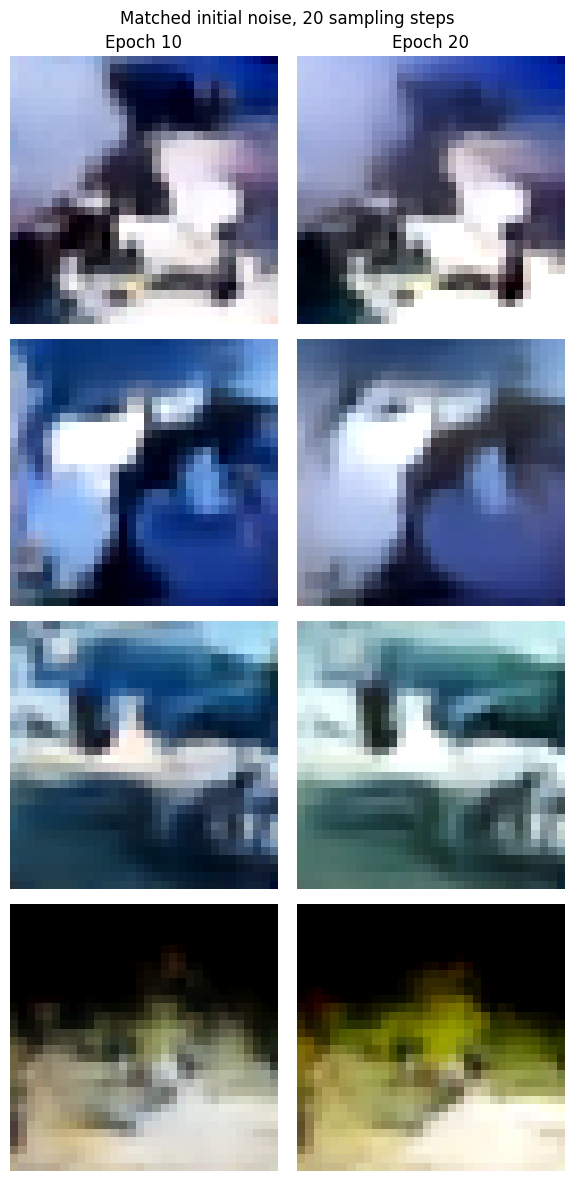

In [18]:
fig, axes = plt.subplots(4, 2, figsize=(6, 12))
for column, checkpoint_path in enumerate([RESUME_PATH, CHECKPOINT_DIR / "diffusion_latest.pth"]):
    pair_checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
    pair_model = DiffusionModel(UNet(IMAGE_SIZE, NUM_CHANNELS), offset_cosine_diffusion_schedule).to(device)
    pair_model.ema_network.load_state_dict(pair_checkpoint["ema_model_state_dict"])
    pair_model.set_normalizer(pair_checkpoint["normalizer_mean"], pair_checkpoint["normalizer_std"])
    pair_samples = pair_model.generate(4, 20, fixed_noise[:4].clone()).cpu()
    for row in range(4):
        axes[row, column].imshow(pair_samples[row].permute(1, 2, 0))
        axes[row, column].axis("off")
        if row == 0:
            axes[row, column].set_title(f"Epoch {pair_checkpoint['epoch']}")
    del pair_model
fig.suptitle("Matched initial noise, 20 sampling steps")
plt.tight_layout()
plt.savefig(SAMPLE_DIR / "epoch_10_vs_20.png", dpi=150, bbox_inches="tight")
plt.show()


## 6. Compare sampling steps

Compare 20, 50, and 100 reverse-diffusion steps with the same final-epoch EMA weights and four identical initial noise tensors. Each column starts from the same noise; the discretization changes with the step count. No training is performed. More steps do not guarantee better visual quality.

Compared checkpoint epoch: 20


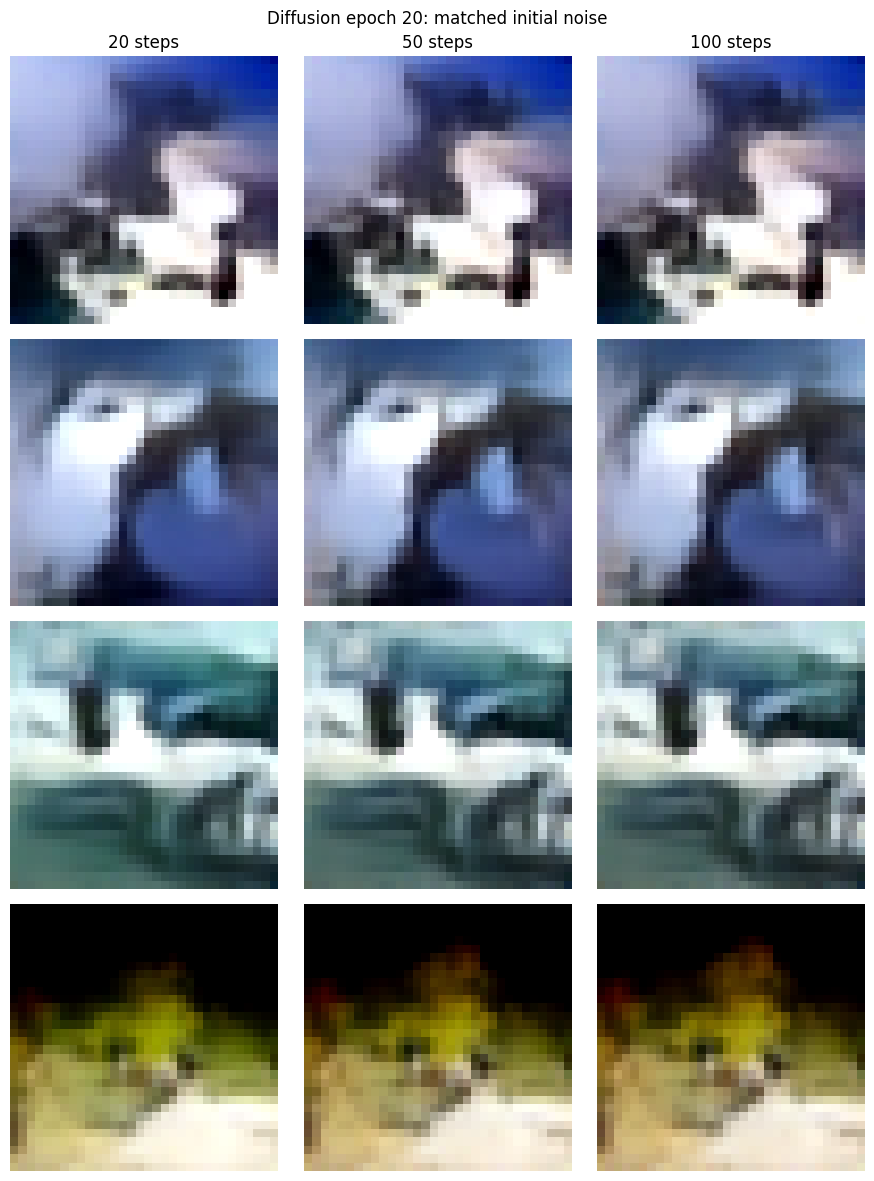

In [17]:
comparison_checkpoint = torch.load(CHECKPOINT_DIR / "diffusion_latest.pth", map_location="cpu", weights_only=True)
comparison_model = DiffusionModel(UNet(IMAGE_SIZE, NUM_CHANNELS), offset_cosine_diffusion_schedule).to(device)
comparison_model.ema_network.load_state_dict(comparison_checkpoint["ema_model_state_dict"])
comparison_model.set_normalizer(comparison_checkpoint["normalizer_mean"], comparison_checkpoint["normalizer_std"])
comparison_model.eval()
comparison_noise = comparison_checkpoint["fixed_noise"][:4].to(device)
fig, axes = plt.subplots(4, 3, figsize=(9, 12))
for column, steps in enumerate([20, 50, 100]):
    comparison_samples = comparison_model.generate(4, steps, comparison_noise.clone()).cpu()
    if not torch.isfinite(comparison_samples).all():
        raise RuntimeError("Non-finite samples in sampling comparison.")
    for row in range(4):
        axes[row, column].imshow(comparison_samples[row].permute(1, 2, 0))
        axes[row, column].axis("off")
        if row == 0:
            axes[row, column].set_title(f"{steps} steps")
fig.suptitle(f"Diffusion epoch {comparison_checkpoint['epoch']}: matched initial noise")
plt.tight_layout()
plt.savefig(SAMPLE_DIR / "sampling_steps_comparison.png", dpi=150, bbox_inches="tight")
plt.show()
print("Compared checkpoint epoch:", comparison_checkpoint["epoch"])
del comparison_model


## 7. Interpretation and limitations

For the four inspected initial noise tensors at epoch 20, 50 and 100 sampling steps changed local colors and boundaries but did not clearly improve object recognizability relative to 20 steps.

With identical initial noise and 20 sampling steps, the epoch-20 samples differ from epoch 10 in color balance and coarse shapes. Neither checkpoint consistently produces clearly identifiable objects in this small comparison. Additional training modestly improved the best observed validation noise MSE, but did not establish a clear improvement in visual realism.

The displayed comparisons contain only four samples and are qualitative. Do not infer a general ranking of models or sampling settings from these images alone.

## 8. Evaluate and export the selected model

Select the checkpoint with the lowest validation noise MSE and evaluate it once on the held-out test set. Save its EMA weights and normalization statistics in this run's models folder. Existing API weights are preserved. Noise MSE alone does not establish perceptual image quality.

In [15]:
checkpoint = torch.load(CHECKPOINT_DIR / "diffusion_best.pth", map_location=device, weights_only=True)
diffusion_model.network.load_state_dict(checkpoint["model_state_dict"])
diffusion_model.ema_network.load_state_dict(checkpoint["ema_model_state_dict"])
diffusion_model.set_normalizer(checkpoint["normalizer_mean"], checkpoint["normalizer_std"])
test_total = 0.0
test_count = 0
for images, _ in tqdm(test_loader, desc="Test noise MSE"):
    loss = diffusion_model.test_step(images.to(device), loss_fn)
    test_total += loss * images.size(0)
    test_count += images.size(0)
print("Selected epoch:", checkpoint["epoch"])
print("Test noise MSE:", test_total / test_count)

checkpoint = torch.load(CHECKPOINT_DIR / "diffusion_best.pth", map_location="cpu", weights_only=True)
export = {name: checkpoint[name] for name in (
    "ema_model_state_dict", "normalizer_mean", "normalizer_std", "image_size", "num_channels", "epoch"
)}
export_path = MODEL_DIR / "cifar10_diffusion.pth"
torch.save(export, export_path)
print("Exported:", export_path)

Selected epoch: 16
Test noise MSE: 0.05729747979640961
Exported: C:\Users\Milan_Chen\Desktop\SEM3\genai 5560\ASS4\outputs\diffusion_continue_to_20_20261118_191217_480448\models\cifar10_diffusion.pth


## 9. Verify the exported model and generate fresh samples

Reload the saved export from disk into the matching API implementation. Compare both networks on CPU to separate serialization correctness from CPU/GPU numerical differences. Verify normalization and generate fresh samples. The selected epoch may differ from the last training epoch.

Reload verification passed.


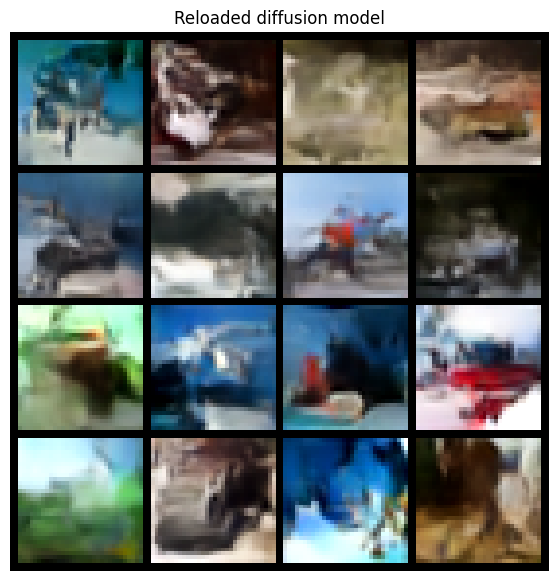

In [16]:
from helper_lib.diffusion import DiffusionModel as APIDiffusionModel
from helper_lib.diffusion import UNet as APIUNet
from helper_lib.diffusion import offset_cosine_diffusion_schedule as api_schedule

export = torch.load(export_path, map_location="cpu", weights_only=True)
reloaded_model = APIDiffusionModel(APIUNet(IMAGE_SIZE, NUM_CHANNELS), api_schedule)
reloaded_model.ema_network.load_state_dict(export["ema_model_state_dict"])
reloaded_model.set_normalizer(export["normalizer_mean"], export["normalizer_std"])
reloaded_model.eval()
reference_network = copy.deepcopy(diffusion_model.ema_network).cpu().eval()
probe = fixed_noise[:2].cpu()
variance = torch.full((2, 1, 1, 1), 0.5)

with torch.no_grad():
    expected = reference_network(probe, variance)
    actual = reloaded_model.ema_network(probe, variance)
torch.testing.assert_close(actual, expected, rtol=1e-4, atol=1e-5)
torch.testing.assert_close(reloaded_model.normalizer_mean, diffusion_model.normalizer_mean.cpu())
torch.testing.assert_close(reloaded_model.normalizer_std, diffusion_model.normalizer_std.cpu())
samples = reloaded_model.generate(16, SAMPLE_STEPS)
save_image(samples, SAMPLE_DIR / "final_samples.png", nrow=4)
show_images(samples, "Reloaded diffusion model")
print("Reload verification passed.")
